In [1]:
1

1

In [2]:
import anndata as ad
import os
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
ROOT_PATH = 'data_coverage_match'

## Download results

In [4]:
def dict_to_pd(d):
    rows = []

    for outer_key, inner in d.items():
        row = {
            "dataset_id": inner["dataset_id"],
            "method_id": inner["method_id"],
        }
        
        # Use values from "d" as column names
        for col_name, value in zip(inner["metric_ids"], inner["metric_values"]):
            row[col_name] = value
            
        rows.append(row)
    
    df = pd.DataFrame(rows, index=d.keys())
    return df

In [5]:
methods_path = f'../{ROOT_PATH}/benchmark/results/metrics/methods/'

In [6]:
file_name_err = 'mean_rowwise_error.h5ad'
file_name_corr = 'mean_rowwise_correlation.h5ad'

In [7]:
methods_err = {}
methods_corr = {}
for item in os.listdir(methods_path):
    if 'mol_emb_learning' in item:
        if 'nn_retraining_with_pseudolabels_mol_emb_subsample_fp' in item:
            name = item.replace('_all_1', '')
        else:
            name = item
        name = name.replace('nn_retraining_with_pseudolabels_mol_emb_learning_missed_subsample_', '')
        stability_path = methods_path + item + '/stability'
        for seed in os.listdir(stability_path):
            
            err = ad.read_h5ad(f'{stability_path}/{seed}/{file_name_err}').uns
            corr = ad.read_h5ad(f'{stability_path}/{seed}/{file_name_corr}').uns
            methods_err[name + '_' + seed] = err
            methods_corr[name + '_' + seed] = corr

In [8]:
df_method_err = dict_to_pd(methods_err)

In [9]:
df_method_corr = dict_to_pd(methods_corr)

In [10]:
df_method_err['method_name'] = df_method_err.index.str.split('_seed_').str[0]
df_method_err['seed'] = df_method_err.index.str.split('_seed_').str[1].astype(int)

In [11]:
df_method_corr['method_name'] = df_method_corr.index.str.split('_seed_').str[0]
df_method_corr['seed'] = df_method_corr.index.str.split('_seed_').str[1].astype(int)

In [12]:
len(df_method_corr['method_name'].unique())

18

## Mean rowwise error

### Methods

In [13]:
df_method_err.sort_values(by="mean_rowwise_rmse")

,dataset_id,method_id,mean_rowwise_rmse,mean_rowwise_mae,method_name,seed
lpm_trainable_all_20_abl_dose_time_coverage_match_seed_0,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.799787,0.565234,lpm_trainable_all_20_abl_dose_time_coverage_match,0
lpm_trainable_all_20_abl_dose_time_coverage_match_seed_13,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.799868,0.564143,lpm_trainable_all_20_abl_dose_time_coverage_match,13
lpm_trainable_all_20_abl_dose_time_coverage_match_seed_14,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.799924,0.564275,lpm_trainable_all_20_abl_dose_time_coverage_match,14
lpm_trainable_all_20_abl_dose_time_coverage_match_seed_4,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.800102,0.564390,lpm_trainable_all_20_abl_dose_time_coverage_match,4
lpm_trainable_all_20_abl_dose_time_coverage_match_seed_12,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.800441,0.564678,lpm_trainable_all_20_abl_dose_time_coverage_match,12
...,...,...,...,...,...,...
chemb1_fixed_chemb1_seed_3,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.875565,0.630928,chemb1_fixed_chemb1,3
chemb1_fixed_chemb1_seed_11,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.875648,0.631354,chemb1_fixed_chemb1,11
chemb1_fixed_chemb1_seed_13,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.876559,0.632508,chemb1_fixed_chemb1,13
chemb1_fixed_chemb1_seed_10,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.879445,0.634101,chemb1_fixed_chemb1,10


In [14]:
df_method_err

,dataset_id,method_id,mean_rowwise_rmse,mean_rowwise_mae,method_name,seed
chemb1_trainable_chemb1_seed_14,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.826149,0.583470,chemb1_trainable_chemb1,14
chemb1_trainable_chemb1_seed_2,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.827562,0.585567,chemb1_trainable_chemb1,2
chemb1_trainable_chemb1_seed_0,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.827621,0.585692,chemb1_trainable_chemb1,0
chemb1_trainable_chemb1_seed_11,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.827051,0.584287,chemb1_trainable_chemb1,11
chemb1_trainable_chemb1_seed_1,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.827986,0.585935,chemb1_trainable_chemb1,1
...,...,...,...,...,...,...
lpm_trainable_all_20_abl_dataset_dose_time_coverage_match_seed_4,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.803818,0.566695,lpm_trainable_all_20_abl_dataset_dose_time_cov...,4
lpm_trainable_all_20_abl_dataset_dose_time_coverage_match_seed_13,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.803872,0.566576,lpm_trainable_all_20_abl_dataset_dose_time_cov...,13
lpm_trainable_all_20_abl_dataset_dose_time_coverage_match_seed_12,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.803525,0.567030,lpm_trainable_all_20_abl_dataset_dose_time_cov...,12
lpm_trainable_all_20_abl_dataset_dose_time_coverage_match_seed_10,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.803936,0.567216,lpm_trainable_all_20_abl_dataset_dose_time_cov...,10


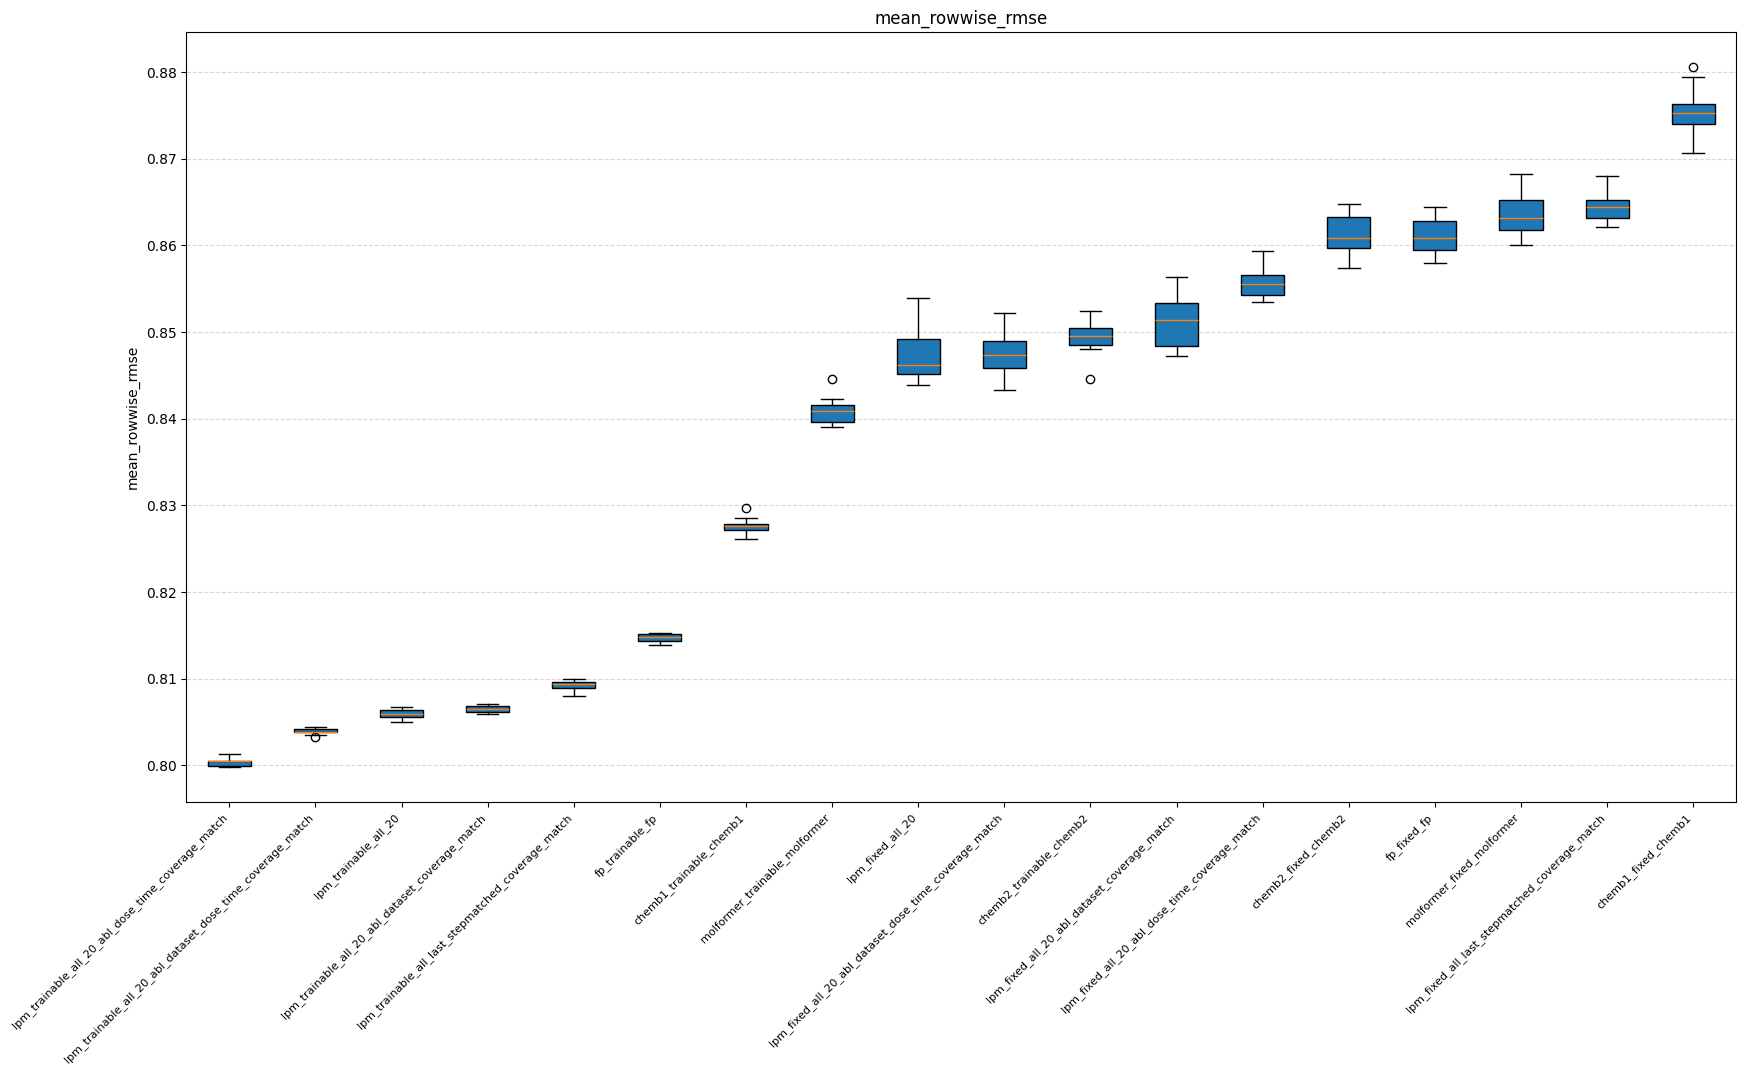

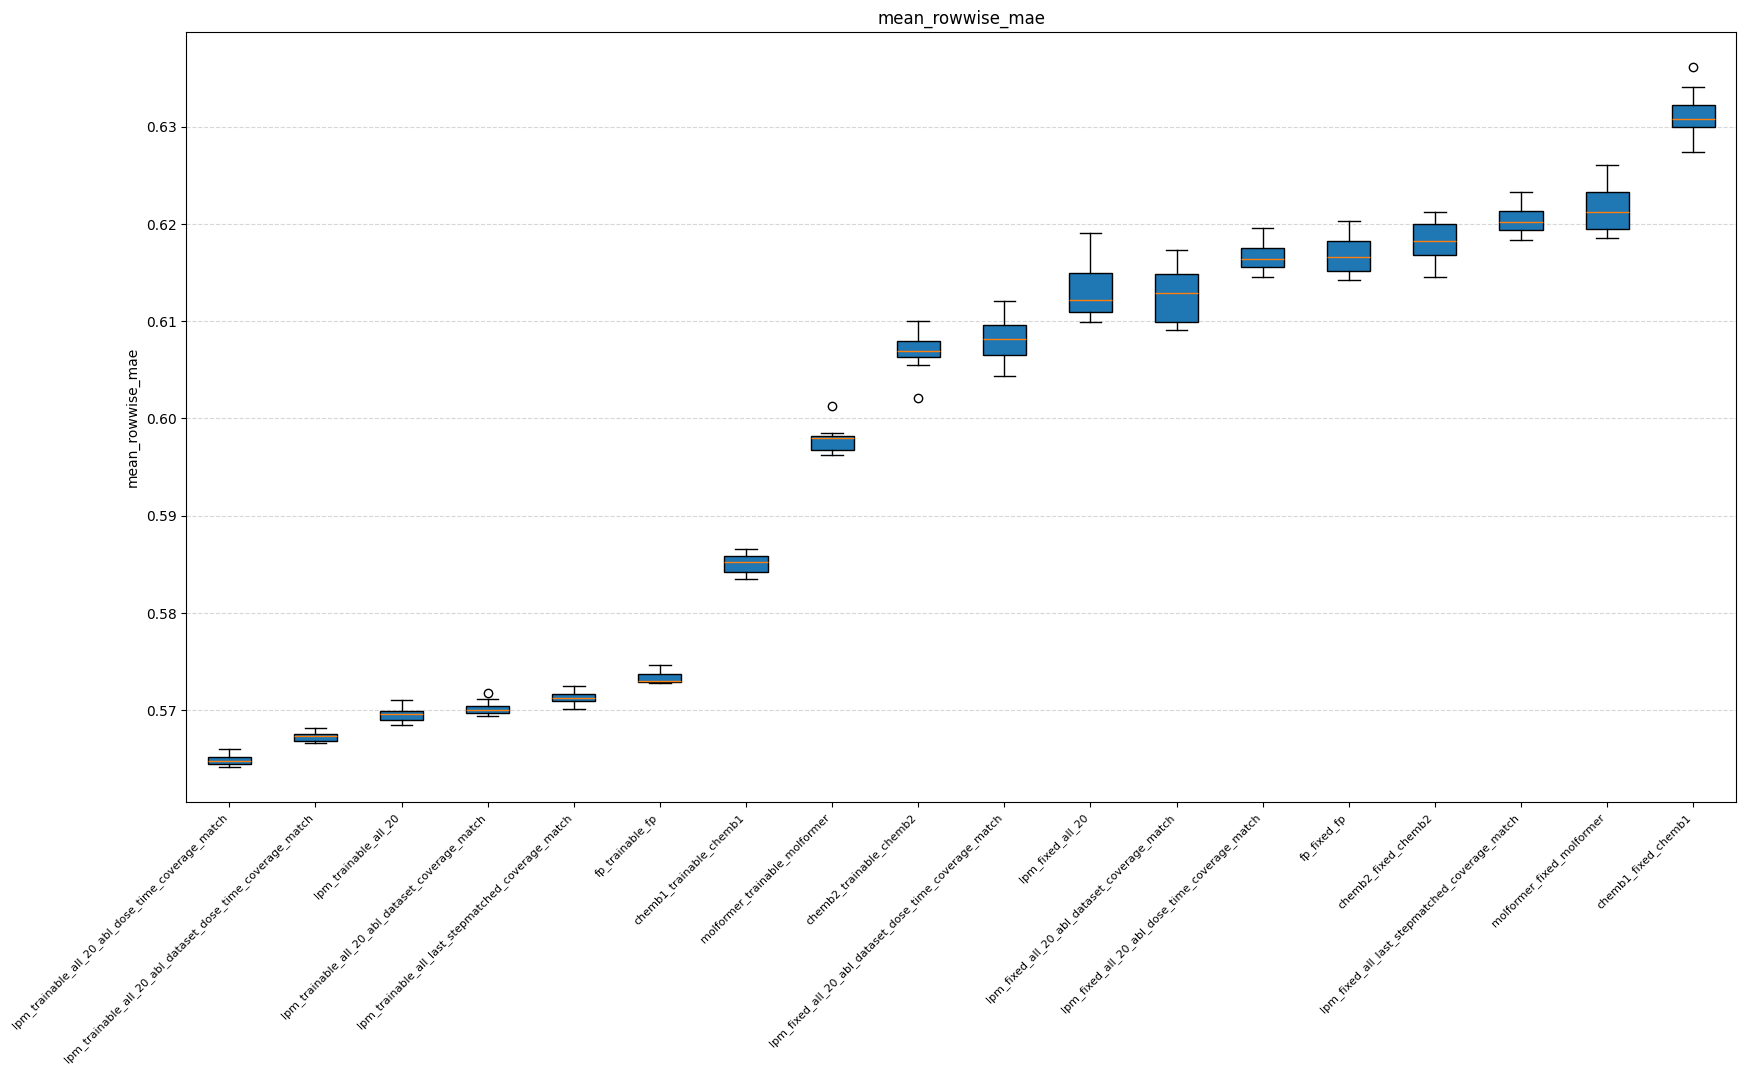

In [15]:
metrics = ["mean_rowwise_rmse", "mean_rowwise_mae"]
#fig, axes = plt.subplots(1, len(metrics), figsize=(6 * len(metrics), 5))
for metric in metrics:
    # collect values per method, ordered by median
    methods_ordered = (
        df_method_err.groupby("method_name")[metric]
        .median()
        .sort_values()
        .index.tolist()
    )
    data_per_method = [
        df_method_err.loc[df_method_err["method_name"] == m, metric].values
        for m in methods_ordered
    ]
    plt.figure(figsize=(20, 10))
    plt.boxplot(data_per_method, patch_artist=True, vert=True)
    plt.xticks(
        range(1, len(methods_ordered) + 1),
        # strip the long common prefix for readability
        [m.replace("nn_retraining_with_pseudolabels_mol_emb_subsample_", "") for m in methods_ordered],
        rotation=45, ha="right", fontsize=8,
    )
    plt.ylabel(metric)
    plt.title(metric)
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.show()
#fig.suptitle("Stability across seeds", fontsize=13, y=1.02)
#plt.tight_layout()


## Mean rowwise correlation

### Methods

In [16]:
df_method_corr.sort_values(by="mean_rowwise_pearson", ascending=False)
#df_method_corr.sort_values(by="mean_rowwise_spearman", ascending=False)

,dataset_id,method_id,mean_rowwise_pearson,mean_rowwise_spearman,mean_rowwise_cosine,method_name,seed
lpm_trainable_all_20_abl_dose_time_coverage_match_seed_14,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.289496,0.275574,0.293299,lpm_trainable_all_20_abl_dose_time_coverage_match,14
lpm_trainable_all_20_abl_dataset_dose_time_coverage_match_seed_0,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.288938,0.274222,0.292779,lpm_trainable_all_20_abl_dataset_dose_time_cov...,0
lpm_trainable_all_20_abl_dose_time_coverage_match_seed_0,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.288566,0.274705,0.292365,lpm_trainable_all_20_abl_dose_time_coverage_match,0
lpm_trainable_all_20_abl_dataset_dose_time_coverage_match_seed_1,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.288529,0.273679,0.292439,lpm_trainable_all_20_abl_dataset_dose_time_cov...,1
lpm_trainable_all_20_abl_dose_time_coverage_match_seed_3,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.288084,0.274784,0.291942,lpm_trainable_all_20_abl_dose_time_coverage_match,3
...,...,...,...,...,...,...,...
chemb1_fixed_chemb1_seed_12,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.210909,0.197492,0.214775,chemb1_fixed_chemb1,12
chemb1_fixed_chemb1_seed_10,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.209400,0.196168,0.213330,chemb1_fixed_chemb1,10
chemb1_fixed_chemb1_seed_1,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.209011,0.196000,0.212912,chemb1_fixed_chemb1,1
chemb1_fixed_chemb1_seed_4,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.208025,0.194533,0.211935,chemb1_fixed_chemb1,4


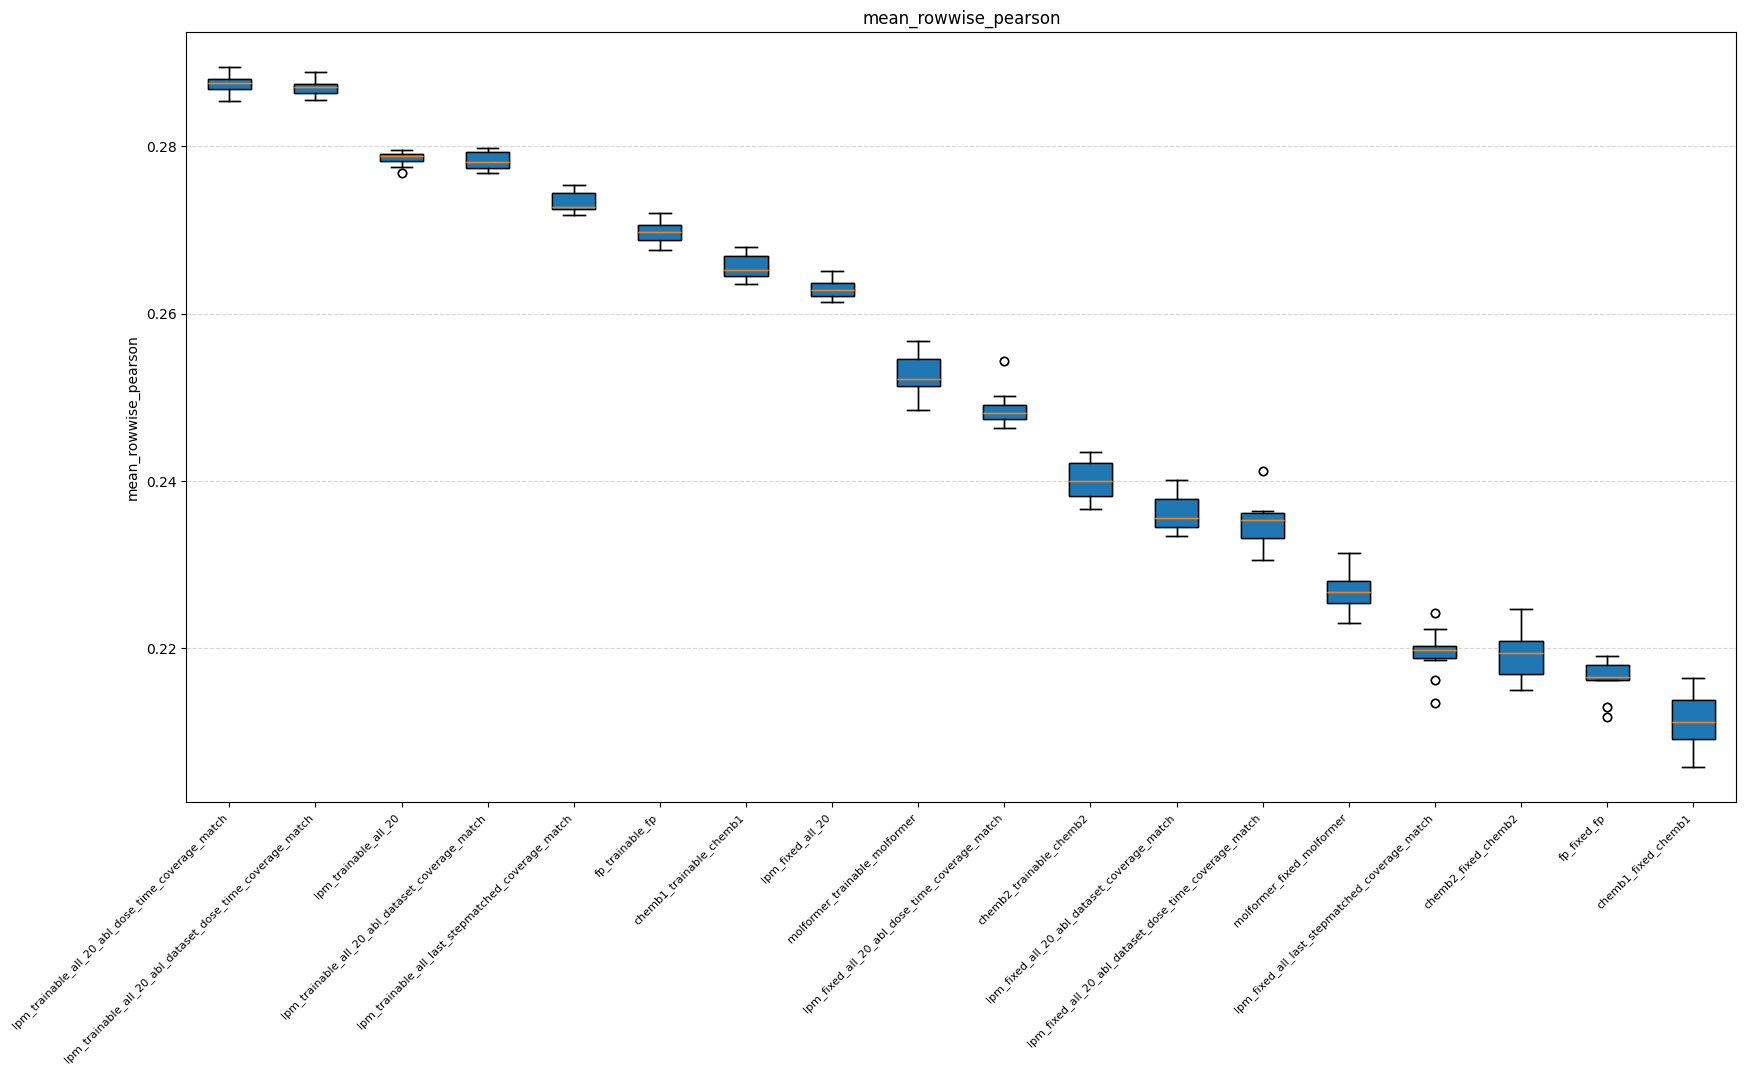

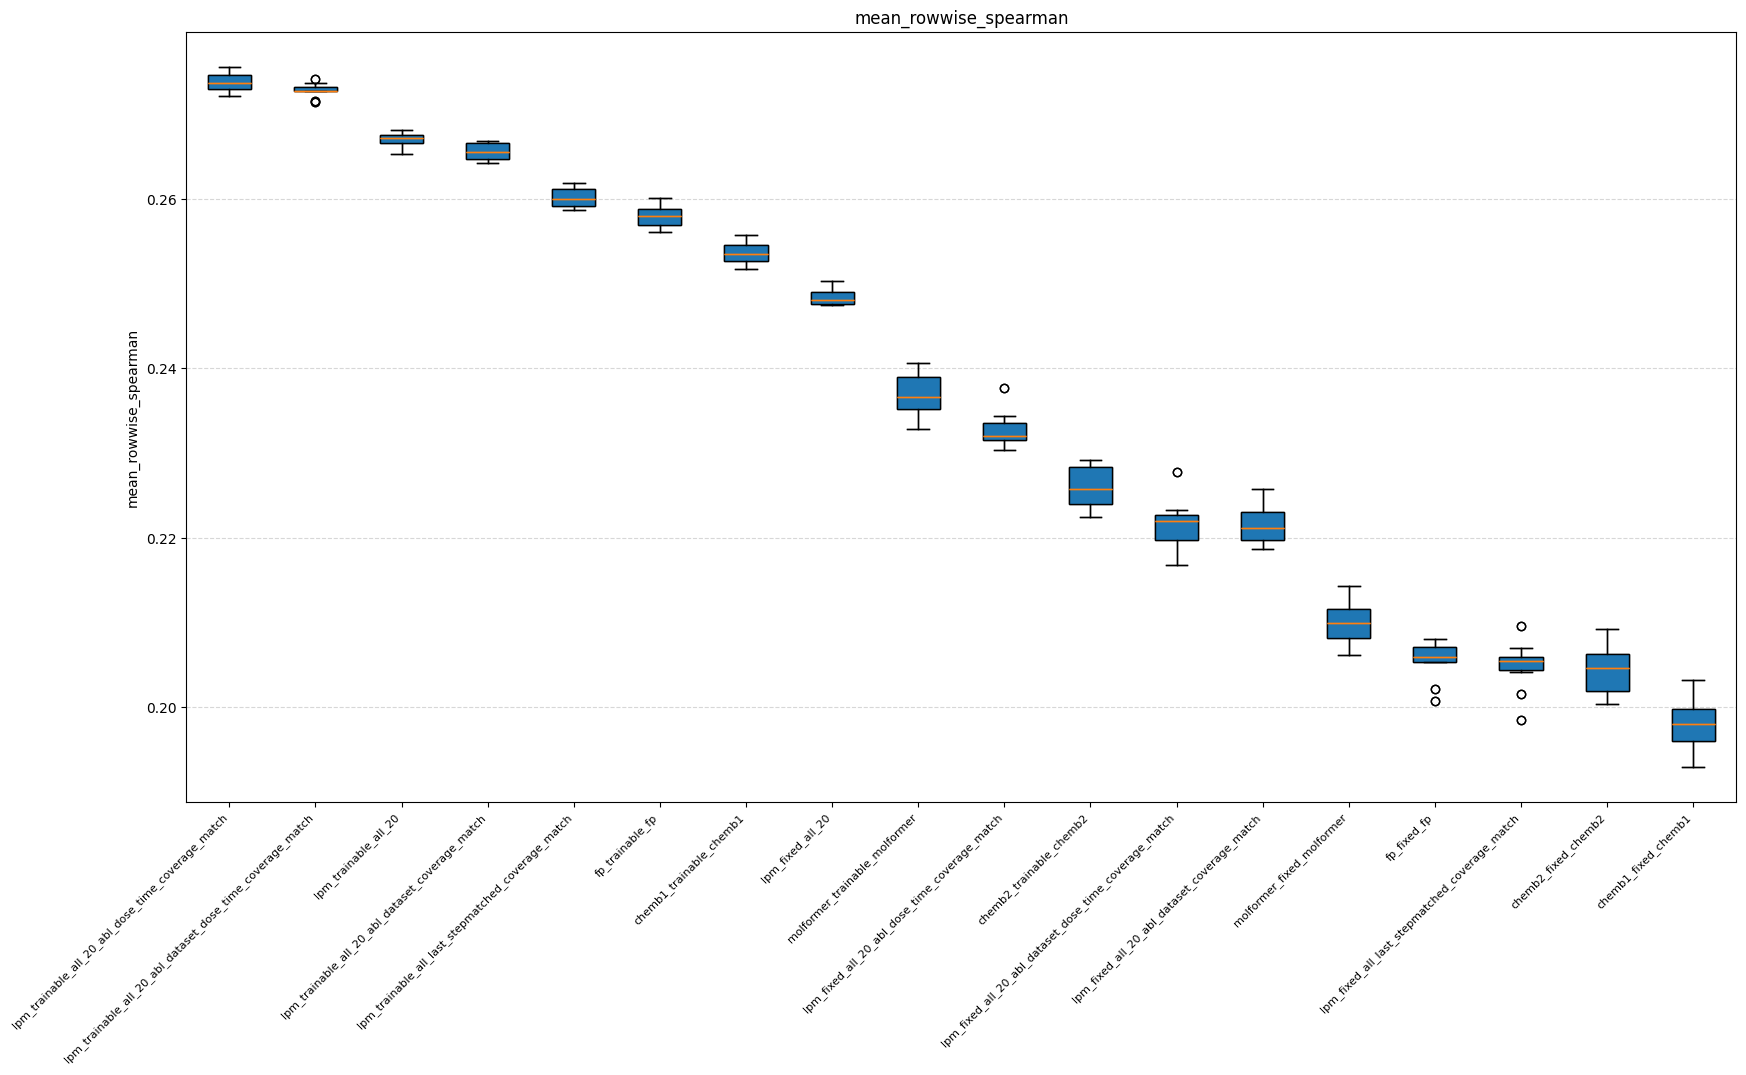

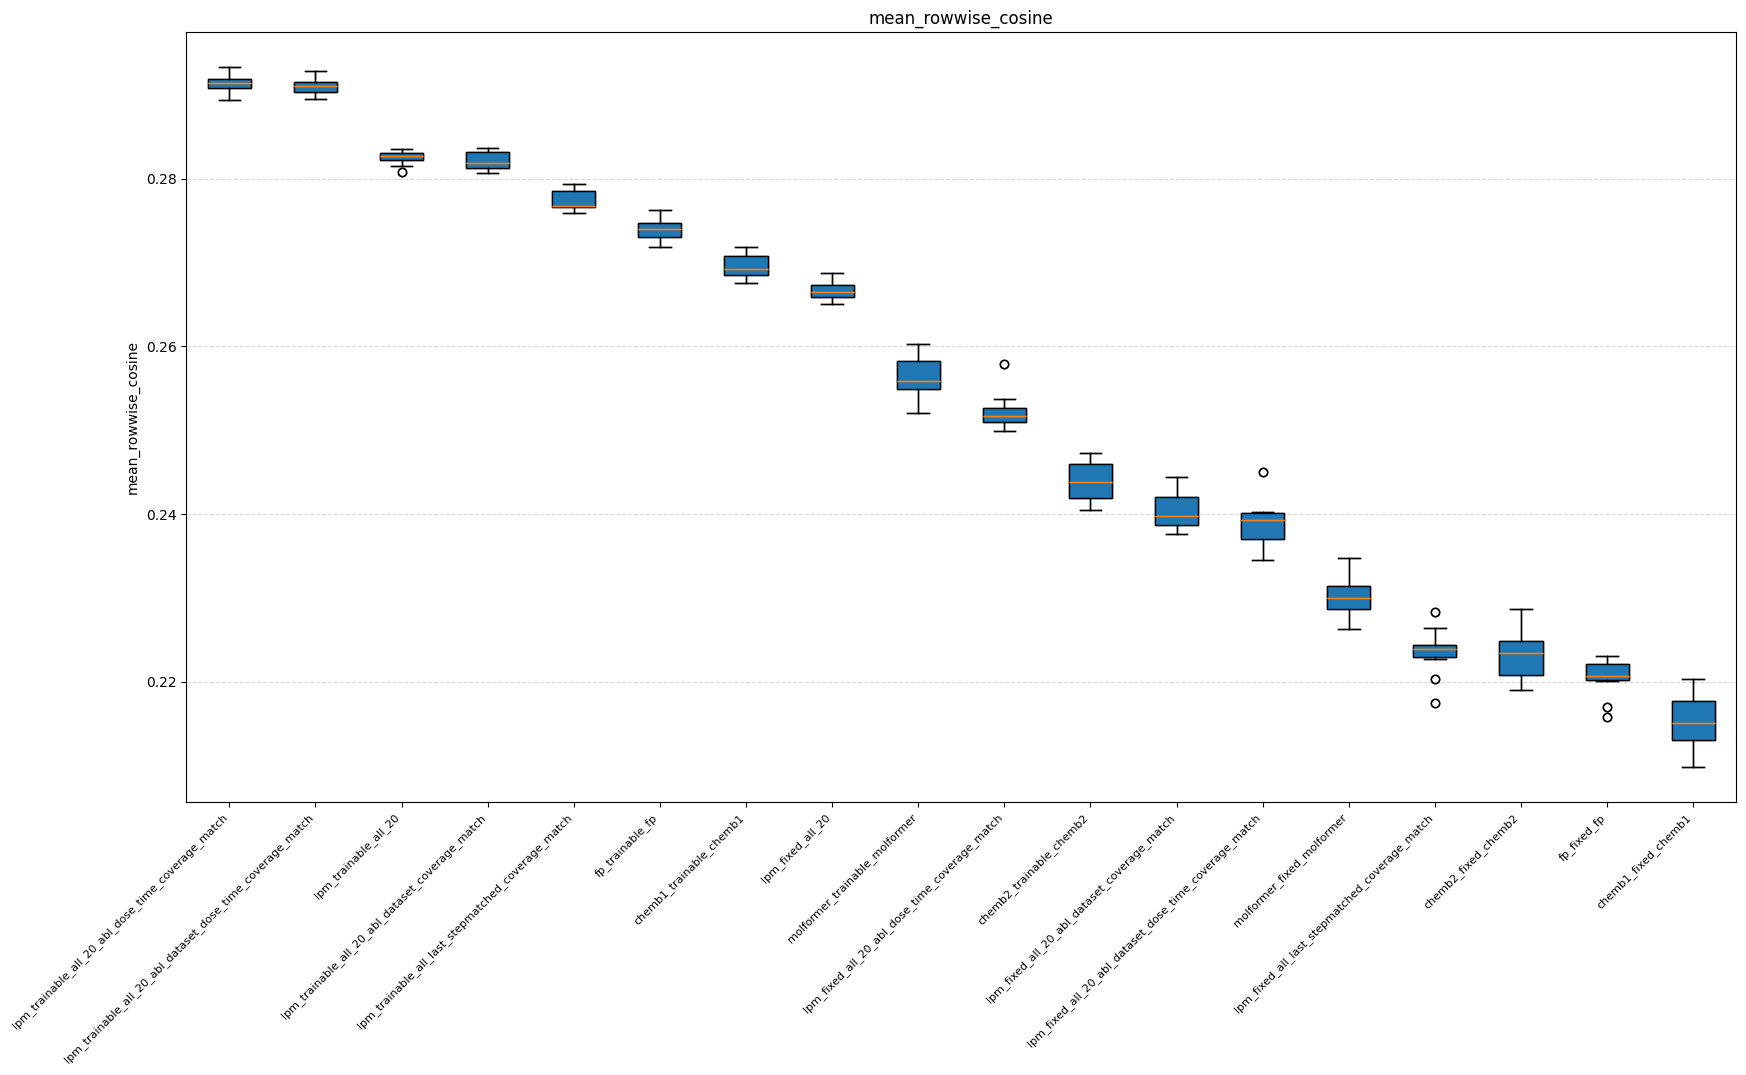

In [17]:
corr_metrics = ["mean_rowwise_pearson", "mean_rowwise_spearman", "mean_rowwise_cosine"]
for metric in corr_metrics:
    # higher correlation is better → sort descending
    methods_ordered = (
        df_method_corr.groupby("method_name")[metric]
        .median()
        .sort_values(ascending=False)
        .index.tolist()
    )
    data_per_method = [
        df_method_corr.loc[df_method_corr["method_name"] == m, metric].values
        for m in methods_ordered
    ]
    plt.figure(figsize=(20, 10))
    plt.boxplot(data_per_method, patch_artist=True, vert=True)
    plt.boxplot(data_per_method, patch_artist=True, vert=True)

    plt.xticks(
        range(1, len(methods_ordered) + 1),
        [m.replace("nn_retraining_with_pseudolabels_mol_emb_subsample_", "") for m in methods_ordered],
        rotation=45, ha="right", fontsize=8,
    )
    plt.ylabel(metric)
    plt.title(metric)
    plt.grid(axis="y", linestyle="--", alpha=0.5)

    plt.show()

In [18]:
df_method_err

,dataset_id,method_id,mean_rowwise_rmse,mean_rowwise_mae,method_name,seed
chemb1_trainable_chemb1_seed_14,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.826149,0.583470,chemb1_trainable_chemb1,14
chemb1_trainable_chemb1_seed_2,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.827562,0.585567,chemb1_trainable_chemb1,2
chemb1_trainable_chemb1_seed_0,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.827621,0.585692,chemb1_trainable_chemb1,0
chemb1_trainable_chemb1_seed_11,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.827051,0.584287,chemb1_trainable_chemb1,11
chemb1_trainable_chemb1_seed_1,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_chemb1...,0.827986,0.585935,chemb1_trainable_chemb1,1
...,...,...,...,...,...,...
lpm_trainable_all_20_abl_dataset_dose_time_coverage_match_seed_4,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.803818,0.566695,lpm_trainable_all_20_abl_dataset_dose_time_cov...,4
lpm_trainable_all_20_abl_dataset_dose_time_coverage_match_seed_13,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.803872,0.566576,lpm_trainable_all_20_abl_dataset_dose_time_cov...,13
lpm_trainable_all_20_abl_dataset_dose_time_coverage_match_seed_12,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.803525,0.567030,lpm_trainable_all_20_abl_dataset_dose_time_cov...,12
lpm_trainable_all_20_abl_dataset_dose_time_coverage_match_seed_10,neurips-2023-data,nn_retraining_with_pseudolabels_mol_emb_lpm_tr...,0.803936,0.567216,lpm_trainable_all_20_abl_dataset_dose_time_cov...,10


In [19]:
df_err_summary = (
    df_method_err
    .groupby("method_name")[metrics]
    .agg(["mean", "std"])
    .sort_values(("mean_rowwise_rmse", "mean"), ascending=True)
    .round(4)
)

display(df_err_summary)



df_corr_summary = (
    df_method_corr
    .groupby("method_name")[corr_metrics]
    .agg(["mean", "std"])
    .sort_values(("mean_rowwise_pearson", "mean"), ascending=False)
    .round(4)
)
display(df_corr_summary)

mean_rowwise_rmse          \
                                                                mean     std   
method_name                                                                    
lpm_trainable_all_20_abl_dose_time_coverage_match             0.8004  0.0005   
lpm_trainable_all_20_abl_dataset_dose_time_cove...            0.8039  0.0004   
lpm_trainable_all_20                                          0.8059  0.0005   
lpm_trainable_all_20_abl_dataset_coverage_match               0.8065  0.0004   
lpm_trainable_all_last_stepmatched_coverage_match             0.8093  0.0006   
fp_trainable_fp                                               0.8147  0.0005   
chemb1_trainable_chemb1                                       0.8276  0.0010   
molformer_trainable_molformer                                 0.8409  0.0017   
lpm_fixed_all_20                                              0.8473  0.0032   
lpm_fixed_all_20_abl_dataset_dose_time_coverage...            0.8475  0.0026   
chemb2_trainable_chemb2                                       0.8493  0.0021   
lpm_fixed_all_20_abl_dataset_coverage_match                   0.8512  0.0032   
lpm_fixed_all_20_abl_dose_time_coverage_match                 0.8556  0.0018   
fp_fixed_fp                                                   0.8610  0.0022   
chemb2_fixed_chemb2                                           0.8613  0.0024   
molformer_fixed_molformer                                     0.8636  0.0027   
lpm_fixed_all_last_stepmatched_coverage_match                 0.8645  0.0018   
chemb1_fixed_chemb1                                           0.8755  0.0029   

                                                   mean_rowwise_mae          
                                                               mean     std  
method_name                                                                  
lpm_trainable_all_20_abl_dose_time_coverage_match            0.5648  0.0006  
lpm_trainable_all_20_abl_dataset_dose_time_cove...           0.5673  0.0006  
lpm_trainable_all_20                                         0.5696  0.0008  
lpm_trainable_all_20_abl_dataset_coverage_match              0.5702  0.0008  
lpm_trainable_all_last_stepmatched_coverage_match            0.5713  0.0008  
fp_trainable_fp                                              0.5734  0.0007  
chemb1_trainable_chemb1                                      0.5851  0.0011  
molformer_trainable_molformer                                0.5979  0.0014  
lpm_fixed_all_20                                             0.6131  0.0029  
lpm_fixed_all_20_abl_dataset_dose_time_coverage...           0.6082  0.0023  
chemb2_trainable_chemb2                                      0.6069  0.0021  
lpm_fixed_all_20_abl_dataset_coverage_match                  0.6127  0.0028  
lpm_fixed_all_20_abl_dose_time_coverage_match                0.6166  0.0016  
fp_fixed_fp                                                  0.6167  0.0021  
chemb2_fixed_chemb2                                          0.6183  0.0023  
molformer_fixed_molformer                                    0.6217  0.0026  
lpm_fixed_all_last_stepmatched_coverage_match                0.6204  0.0017  
chemb1_fixed_chemb1                                          0.6313  0.0025

mean_rowwise_pearson  \
                                                                   mean   
method_name                                                               
lpm_trainable_all_20_abl_dose_time_coverage_match                0.2875   
lpm_trainable_all_20_abl_dataset_dose_time_cove...               0.2871   
lpm_trainable_all_20                                             0.2786   
lpm_trainable_all_20_abl_dataset_coverage_match                  0.2783   
lpm_trainable_all_last_stepmatched_coverage_match                0.2733   
fp_trainable_fp                                                  0.2697   
chemb1_trainable_chemb1                                          0.2656   
lpm_fixed_all_20                                                 0.2630   
molformer_trainable_molformer                                    0.2527   
lpm_fixed_all_20_abl_dose_time_coverage_match                    0.2487   
chemb2_trainable_chemb2                                          0.2400   
lpm_fixed_all_20_abl_dataset_coverage_match                      0.2362   
lpm_fixed_all_20_abl_dataset_dose_time_coverage...               0.2350   
molformer_fixed_molformer                                        0.2267   
lpm_fixed_all_last_stepmatched_coverage_match                    0.2194   
chemb2_fixed_chemb2                                              0.2193   
fp_fixed_fp                                                      0.2164   
chemb1_fixed_chemb1                                              0.2112   

                                                            \
                                                       std   
method_name                                                  
lpm_trainable_all_20_abl_dose_time_coverage_match   0.0011   
lpm_trainable_all_20_abl_dataset_dose_time_cove...  0.0010   
lpm_trainable_all_20                                0.0009   
lpm_trainable_all_20_abl_dataset_coverage_match     0.0012   
lpm_trainable_all_last_stepmatched_coverage_match   0.0012   
fp_trainable_fp                                     0.0013   
chemb1_trainable_chemb1                             0.0015   
lpm_fixed_all_20                                    0.0011   
molformer_trainable_molformer                       0.0025   
lpm_fixed_all_20_abl_dose_time_coverage_match       0.0023   
chemb2_trainable_chemb2                             0.0025   
lpm_fixed_all_20_abl_dataset_coverage_match         0.0024   
lpm_fixed_all_20_abl_dataset_dose_time_coverage...  0.0029   
molformer_fixed_molformer                           0.0025   
lpm_fixed_all_last_stepmatched_coverage_match       0.0030   
chemb2_fixed_chemb2                                 0.0032   
fp_fixed_fp                                         0.0024   
chemb1_fixed_chemb1                                 0.0033   

                                                   mean_rowwise_spearman  \
                                                                    mean   
method_name                                                                
lpm_trainable_all_20_abl_dose_time_coverage_match                 0.2738   
lpm_trainable_all_20_abl_dataset_dose_time_cove...                0.2728   
lpm_trainable_all_20                                              0.2670   
lpm_trainable_all_20_abl_dataset_coverage_match                   0.2656   
lpm_trainable_all_last_stepmatched_coverage_match                 0.2602   
fp_trainable_fp                                                   0.2580   
chemb1_trainable_chemb1                                           0.2536   
lpm_fixed_all_20                                                  0.2484   
molformer_trainable_molformer                                     0.2370   
lpm_fixed_all_20_abl_dose_time_coverage_match                     0.2327   
chemb2_trainable_chemb2                                           0.2260   
lpm_fixed_all_20_abl_dataset_coverage_match                       0.2216   
lpm_fixed_all_20_abl_dataset_dos

In [20]:
os.makedirs('../results', exist_ok=True)

In [21]:
df_err_summary.to_csv('../results/df_err_summary_coverage_match.csv')
df_corr_summary.to_csv('../results/df_corr_summary_coverage_match.csv')